In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

nltk.download('stopwords')
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kotha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
df = pd.read_csv("IMDB Dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing values:
 review       0
sentiment    0
dtype: int64

Duplicate rows: 418

Class distribution:
 sentiment
positive    25000
negative    25000
Name: count, dtype: int64


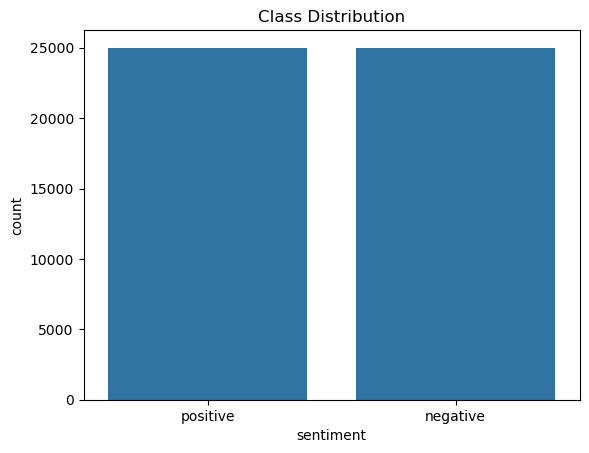

In [5]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass distribution:\n", df['sentiment'].value_counts())

sns.countplot(x='sentiment', data=df)
plt.title("Class Distribution")
plt.show()

In [6]:
# 1. Remove duplicates and missing values
df = df.drop_duplicates().dropna().reset_index(drop=True)

# 2. Use 20,000 reviews so training is fast
df = df.sample(20000, random_state=42).reset_index(drop=True)

# 3. Encode labels: positive = 1, negative = 0
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

print("After cleaning:", df.shape)

After cleaning: (20000, 3)


In [7]:
stop_words = set(stopwords.words('english'))
stop_words -= {'not', 'no', 'nor'}   # keep negations, they matter for sentiment

def clean_text(text):
    text = re.sub(r'<.*?>', ' ', text)          # remove HTML tags
    text = text.lower()                          # lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)        # remove punctuation and numbers
    words = [w for w in text.split() if w not in stop_words]   # remove stopwords
    return ' '.join(words)

print("Before:", df['review'][0][:200])
df['clean_review'] = df['review'].apply(clean_text)
print("After :", df['clean_review'][0][:200])

Before: "Soul Plane" is a horrible attempt at comedy that only should appeal people with thick skulls, bloodshot eyes and furry pawns. <br /><br />The plot is not only incoherent but also non-existent, acting
After : soul plane horrible attempt comedy appeal people thick skulls bloodshot eyes furry pawns plot not incoherent also non existent acting mostly sub sub par gang highly moronic dreadful characters thrown 


count    20000.000000
mean       119.678000
std         90.807934
min          4.000000
25%         64.000000
50%         89.000000
75%        145.000000
max       1426.000000
Name: length, dtype: float64


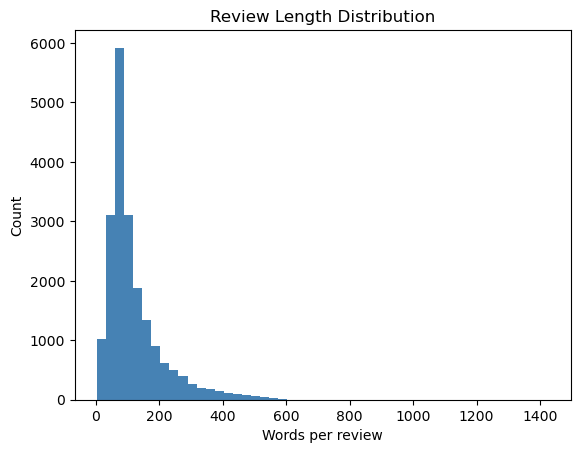

In [8]:
df['length'] = df['clean_review'].apply(lambda x: len(x.split()))
print(df['length'].describe())

plt.hist(df['length'], bins=50, color='steelblue')
plt.xlabel("Words per review"); plt.ylabel("Count")
plt.title("Review Length Distribution")
plt.show()

In [9]:
max_words = 10000   # vocabulary size
max_len = 200       # sequence length

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_review'])

sequences = tokenizer.texts_to_sequences(df['clean_review'])
X = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')
y = df['label'].values

print("X shape:", X.shape, "| y shape:", y.shape)
print("Example sequence:", X[0][:20])

X shape: (20000, 200) | y shape: (20000,)
Example sequence: [1220 1445  360  473   98 1226   19 3809    1    1  374 9092    1   37
    4 3213   20  515 2885   40]


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (16000, 200) | Test: (4000, 200)


In [11]:
model = keras.Sequential([
    layers.Input(shape=(max_len,)),
    layers.Embedding(max_words, 64),
    layers.LSTM(64),
    layers.Dropout(0.4),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=8,
                    batch_size=128,
                    validation_split=0.2,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/8
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 179ms/step - accuracy: 0.5093 - loss: 0.6929 - val_accuracy: 0.5056 - val_loss: 0.6928
Epoch 2/8
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.5204 - loss: 0.6883 - val_accuracy: 0.5297 - val_loss: 0.6910
Epoch 3/8
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.5514 - loss: 0.6649 - val_accuracy: 0.5181 - val_loss: 0.6945
Epoch 4/8
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.5714 - loss: 0.6296 - val_accuracy: 0.5322 - val_loss: 0.7187


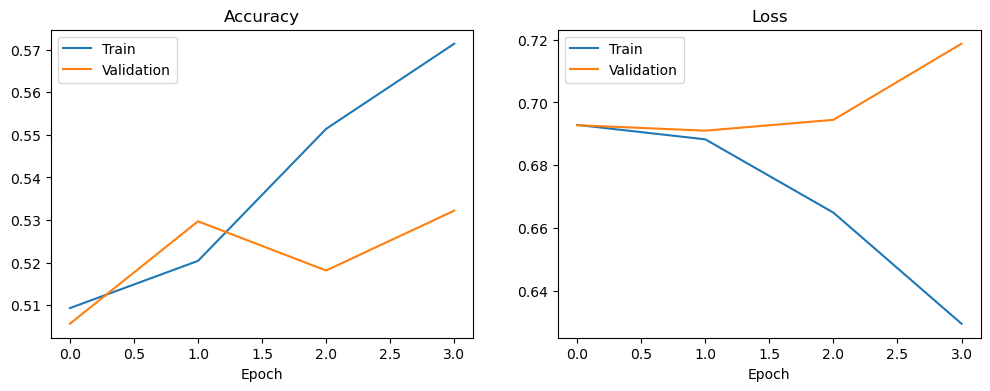

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['accuracy'], label='Train')
ax[0].plot(history.history['val_accuracy'], label='Validation')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(history.history['loss'], label='Train')
ax[1].plot(history.history['val_loss'], label='Validation')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.show()

Test Accuracy: 0.5232
Test Loss    : 0.6910
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step

Classification Report:

              precision    recall  f1-score   support

    Negative       0.51      0.95      0.66      1998
    Positive       0.65      0.10      0.18      2002

    accuracy                           0.52      4000
   macro avg       0.58      0.52      0.42      4000
weighted avg       0.58      0.52      0.42      4000



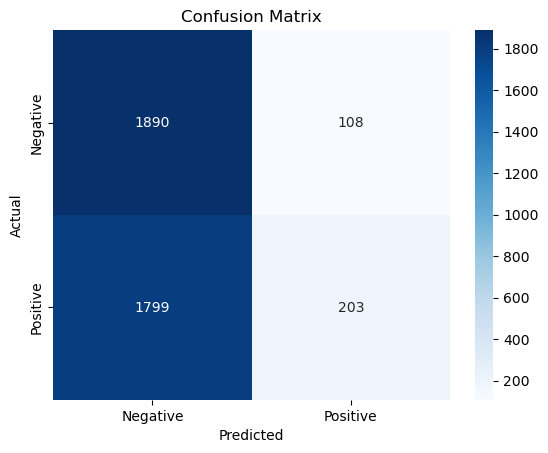

In [14]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {acc:.4f}")
print(f"Test Loss    : {loss:.4f}")

y_pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
plt.show()

In [15]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    pad = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')
    p = model.predict(pad, verbose=0)[0][0]
    label = "Positive" if p > 0.5 else "Negative"
    print(f"Review    : {text}\nPrediction: {label} (score = {p:.3f})\n")

predict_sentiment("This movie was absolutely fantastic, the acting was brilliant!")
predict_sentiment("Worst film ever. Boring story and a complete waste of time.")
predict_sentiment("It was okay, not great but not terrible either.")

Review    : This movie was absolutely fantastic, the acting was brilliant!
Prediction: Negative (score = 0.496)

Review    : Worst film ever. Boring story and a complete waste of time.
Prediction: Negative (score = 0.496)

Review    : It was okay, not great but not terrible either.
Prediction: Negative (score = 0.496)



In [16]:
model.save("sentiment_lstm_model.keras")
df[['review', 'sentiment']].to_csv("imdb_sample_20k.csv", index=False)  # smaller CSV for GitHub
print("Model and sample CSV saved.")

Model and sample CSV saved.
